Cell 1  Imports

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))
from config import ANOMALY_ANALYSIS, HOTSPOT_CLUSTERED, OUTPUT_DIR, TRAJECTORY_ANALYSIS
from temporal_utils import parse_local_naive_series

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Cell 2 — Load Data

In [2]:
df = pd.read_csv(HOTSPOT_CLUSTERED)

print(df.shape)
df.head()

(240654, 34)


,id,latitude,longitude,location,vehicle_number,vehicle_type,description,violation_type,offence_code,created_datetime,...,violations_list,num_violations,max_severity,vehicle_weight,junction_weight,hour,day_of_week,month,is_weekend,cluster_id
0,FKID000000,12.925557,77.618665,"18th Main Road, Block 2, Koramangala, Bengalur...",FKN00GL0000,CAR,NaN,"[""WRONG PARKING"",""PARKING NEAR ROAD CROSSING""]","[112,104]",2023-11-20 05:58:46,...,"['WRONG PARKING', 'PARKING NEAR ROAD CROSSING']",2,6,1.5,1.000000,5.0,Monday,11.0,0.0,0.0
1,FKID000001,12.905463,77.700778,"Sarjapura Main Road, The Grove, Janatha Colony...",FKN00GL0001,CAR,NaN,"[""NO PARKING""]",[113],2023-11-25 04:16:46,...,['NO PARKING'],1,1,1.5,1.000000,4.0,Saturday,11.0,1.0,-1.0
2,FKID000002,12.925449,77.618504,"Koramangala 2nd Block, Kormangala West, Bengal...",FKN00GL0002,CAR,NaN,"[""WRONG PARKING"",""PARKING IN A MAIN ROAD""]","[112,107]",2023-11-20 05:57:46,...,"['WRONG PARKING', 'PARKING IN A MAIN ROAD']",2,5,1.5,1.000000,5.0,Monday,11.0,0.0,0.0
3,FKID000003,12.956521,77.518618,"6th Cross Road, Manasa Layout, Nagarbhavi, Ben...",FKN00GL0003,SCOOTER,NaN,"[""NO PARKING""]",[113],2023-11-16 12:17:46,...,['NO PARKING'],1,1,1.0,1.000000,12.0,Thursday,11.0,0.0,1.0
4,FKID000004,12.977767,77.580545,"Kalidasa Road, Gandhinagar, Nehru Nagar, Benga...",FKN00GL0004,TANKER,NaN,"[""NO PARKING""]",[113],2023-11-22 10:26:46,...,['NO PARKING'],1,1,4.0,0.074066,10.0,Wednesday,11.0,0.0,2.0


Cell 3 ? Datetime

> Monthly trend analysis uses the same local event timestamp generated upstream. No timezone shift is applied here because `created_datetime` has already been converted from UTC to `Asia/Kolkata`.


In [3]:
# `created_datetime` was converted from UTC to Asia/Kolkata in the
# preprocessing stage before being saved to outputs/hotspot_clustered.csv.
df["created_datetime"] = parse_local_naive_series(
    df["created_datetime"],
    "created_datetime",
)

df["year_month"] = (
    df["created_datetime"]
    .dt.to_period("M")
)

monthly_counts_global = (
    df.groupby("year_month")
    .size()
    .sort_index()
)

print(monthly_counts_global)


created_datetime:
  total rows: 240654
  valid timestamps: 240649
  null percentage: 0.00%
  Parsed as timezone-naive local event time because upstream preprocessing already converted UTC to Asia/Kolkata.
year_month
2023-11    32661
2023-12    47189
2024-01    44094
2024-02    48146
2024-03    53127
2024-04    15432
Freq: M, dtype: int64


Cell 4 — Monthly Violation Counts Per Cluster

In [4]:
monthly_counts = (
    df[df["cluster_id"] != -1]
    .groupby(
        ["cluster_id", "year_month"]
    )
    .size()
    .reset_index(name="violations")
)

monthly_counts.head()

,cluster_id,year_month,violations
0,0.0,2023-11,3
1,0.0,2023-12,87
2,0.0,2024-01,109
3,0.0,2024-02,154
4,0.0,2024-03,67


Cell 5 — Create Pivot Table  Rows: cluster, Columns: month, Values: violation

In [5]:
monthly_pivot = (
    monthly_counts
    .pivot(
        index="cluster_id",
        columns="year_month",
        values="violations"
    )
    .fillna(0)
)

monthly_pivot.head()

year_month,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04
cluster_id,,,,,,
0.0,3.0,87.0,109.0,154.0,67.0,7.0
1.0,49.0,70.0,95.0,46.0,129.0,38.0
2.0,6782.0,9800.0,9019.0,8879.0,10353.0,3425.0
3.0,3509.0,2490.0,3949.0,3156.0,4772.0,1369.0
4.0,215.0,241.0,285.0,277.0,283.0,21.0


Cell 6 — Verify Shape

In [6]:
print(monthly_pivot.shape)

(506, 6)


### Cell 7 — Trajectory Slopes

The trajectory regression uses data up to and including the latest complete month.

> **Note**: April 2024 is excluded from the regression as it is an incomplete observation period. The trajectory is fit on data from November 2023 through March 2024.

The resulting trajectory represents the trend in **recorded violation counts** over the observed months. It does not establish causality or prove that actual illegal parking increased or decreased.

In [7]:
trajectory_pivot = monthly_pivot.loc[:, monthly_pivot.columns <= pd.Period("2024-03", freq="M")]

slopes = []

for cluster_id, row in trajectory_pivot.iterrows():

    y = row.values
    active_months = np.count_nonzero(y)

    if active_months < 2:
        slopes.append(
            [cluster_id, np.nan, np.nan]
        )
        continue

    X = np.arange(len(y)).reshape(-1,1)

    model = LinearRegression()
    model.fit(X, y)

    pred = model.predict(X)
    r2 = r2_score(y, pred)

    slopes.append(
        [cluster_id, model.coef_[0], r2]
    )

trajectory_df = pd.DataFrame(
    slopes,
    columns=["cluster_id", "slope", "r2"]
)

trajectory_df.head()

,cluster_id,slope,r2
0,0.0,19.5,0.307049
1,1.0,13.6,0.383830
2,2.0,622.1,0.523016
3,3.0,319.2,0.347763
4,4.0,17.2,0.772670


Cell 8 — Visualize Slope Distribution

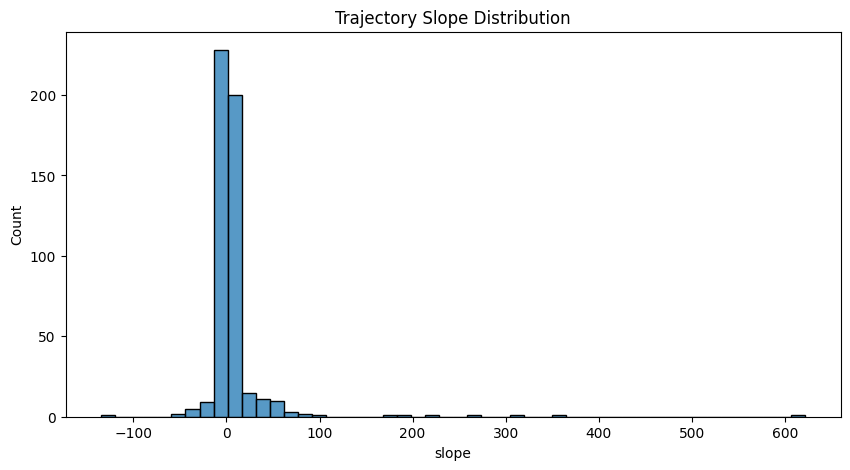

In [8]:
plt.figure(figsize=(10,5))

sns.histplot(
    trajectory_df["slope"],
    bins=50
)

plt.title("Trajectory Slope Distribution")
plt.show()

Cell 9 — Data Driven Thresholds

In [9]:
valid_slopes = trajectory_df["slope"].dropna()

declining_threshold = (
    valid_slopes
    .quantile(0.25)
)

escalating_threshold = (
    valid_slopes
    .quantile(0.75)
)

print("Declining:", declining_threshold)
print("Escalating:", escalating_threshold)

Declining: -1.3
Escalating: 5.2


Cell 10 — Assign Labels

In [10]:
def classify_slope(x):

    if pd.isna(x):
        return "Insufficient History"

    if x >= escalating_threshold:
        return "Escalating"

    elif x <= declining_threshold:
        return "Declining"

    else:
        return "Stable"

trajectory_df["trajectory"] = (
    trajectory_df["slope"]
    .apply(classify_slope)
)

trajectory_df.head()

,cluster_id,slope,r2,trajectory
0,0.0,19.5,0.307049,Escalating
1,1.0,13.6,0.383830,Escalating
2,2.0,622.1,0.523016,Escalating
3,3.0,319.2,0.347763,Escalating
4,4.0,17.2,0.772670,Escalating


Cell 11 — Check Distribution

In [11]:
trajectory_df["trajectory"].value_counts()

trajectory
Stable                  246
Escalating              124
Declining               124
Insufficient History     12
Name: count, dtype: int64

Cell 12 — Top Escalating Hotspots

In [12]:
trajectory_df.sort_values(
    "slope",
    ascending=False
)[
    [
        "cluster_id",
        "slope",
        "r2",
        "trajectory"
    ]
].head(20)

,cluster_id,slope,r2,trajectory
2,2.0,622.1,0.523016,Escalating
9,9.0,362.5,0.705082,Escalating
3,3.0,319.2,0.347763,Escalating
56,56.0,261.5,0.944602,Escalating
31,31.0,223.9,0.767317,Escalating
24,24.0,183.7,0.877700,Escalating
6,6.0,170.0,0.896141,Escalating
64,64.0,101.1,0.286837,Escalating
39,39.0,83.1,0.899013,Escalating
23,23.0,82.2,0.570452,Escalating


### Cell 13 — Anomaly Detection Baseline

Calculate the historical mean and standard deviation for anomaly detection.

> **Note**: `March 2024` (the evaluation month) is excluded from the historical baseline to avoid including the current month in its own evaluation. The baseline is calculated using data from November 2023 through February 2024.

In [13]:
latest_month = pd.Period("2024-03", freq="M")

historical_months = monthly_pivot.columns[
    monthly_pivot.columns < latest_month
]

cluster_month_stats = (
    monthly_pivot[historical_months]
    .agg(
        ["mean", "std"],
        axis=1
    )
)

cluster_month_stats.head()

,mean,std
cluster_id,,
0.0,88.25,63.305476
1.0,65.00,22.671568
2.0,8620.00,1290.597536
3.0,3276.00,616.282944
4.0,254.50,32.552522


### Cell 14 — Current Month Selection

March 2024 is used as the current analysis month because it is the latest **complete** month in the available dataset. April is excluded because its observation period is incomplete.

In [14]:
print("Global Monthly Counts:")
print(monthly_counts_global)

print("\nSelected Analysis Month:")
print(latest_month)

Global Monthly Counts:
year_month
2023-11    32661
2023-12    47189
2024-01    44094
2024-02    48146
2024-03    53127
2024-04    15432
Freq: M, dtype: int64

Selected Analysis Month:
2024-03


### Cell 15 — Add Current Month Count

In [15]:
cluster_month_stats["current_month"] = (
    monthly_pivot[latest_month]
)

### Cell 16 — Z-Score Calculation

In [16]:
def compute_z(row):

    if pd.isna(row["std"]):
        return np.nan

    if row["std"] == 0:
        return np.nan

    if row["mean"] == 0:
        return np.nan

    return (
        row["current_month"]
        - row["mean"]
    ) / row["std"]

cluster_month_stats["z_score"] = (
    cluster_month_stats
    .apply(compute_z, axis=1)
)

### Cell 17 — Anomaly Labels

> A Z-score above **1.5** is used as a project-defined operational threshold for flagging an unusually high current-month violation count relative to the hotspot's historical baseline.

In [17]:
def anomaly_label(z):

    if pd.isna(z):
        return "Insufficient History"

    elif z > 1.5:
        return "Abnormal Surge"

    else:
        return "Normal"

cluster_month_stats["anomaly_status"] = (
    cluster_month_stats["z_score"]
    .apply(anomaly_label)
)

### Cell 18 — Anomaly Watchlist

In [18]:
watchlist = (
    cluster_month_stats[
        cluster_month_stats[
            "anomaly_status"
        ] == "Abnormal Surge"
    ]
    .sort_values(
        "z_score",
        ascending=False
    )
)

watchlist.head(20)

,mean,std,current_month,z_score,anomaly_status
cluster_id,,,,,
380.0,0.25,0.500000,32.0,63.500000,Abnormal Surge
229.0,0.75,1.500000,79.0,52.166667,Abnormal Surge
505.0,0.50,0.577350,23.0,38.971143,Abnormal Surge
178.0,2.25,1.500000,51.0,32.500000,Abnormal Surge
235.0,1.00,0.816497,24.0,28.169132,Abnormal Surge
122.0,1.75,1.707825,48.0,27.081227,Abnormal Surge
424.0,0.50,0.577350,12.0,19.918584,Abnormal Surge
341.0,1.00,1.414214,29.0,19.798990,Abnormal Surge
423.0,1.25,1.500000,26.0,16.500000,Abnormal Surge


### Cell 19 — Save Outputs

In [19]:
trajectory_df.to_csv(
    TRAJECTORY_ANALYSIS,
    index=False
)

cluster_month_stats.to_csv(
    ANOMALY_ANALYSIS
)

print("Saved")

Saved


In [20]:
monthly_counts_global

year_month
2023-11    32661
2023-12    47189
2024-01    44094
2024-02    48146
2024-03    53127
2024-04    15432
Freq: M, dtype: int64